In [50]:
import pandas as pd
import numpy as np
from math import e
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", None)


column_types = {
    "id": "Int64",
    "osm_id": "str",
    "addr_street": "str",
    "addr_number": "str",
    "ground_floor_group": "str",
    "ground_floor_function": "str",
    "upper_floor_group": "str",
    "upper_floor_function": "str",
    "number_of_storeys": "Int64",
    "is_mixed_use": "boolean",
    "build_year_est": "Int64",
    "arch_style": "str",
    "condition": "Int64",
    "max_height": "float64",
    "is_heritage": "str",
    "source": "str",
    "confidence": "Int64",
    "date_of_checking": "str",
    "number_of_functions": "Int64",
}

In [ ]:
data_gdynia = pd.read_csv(
    "../data/processed/fixed/srodmiescie.csv",
    sep=";",
    index_col=0,
    dtype=column_types,
    parse_dates=["date_of_checking"],
)
data_gdynia

,osm_id,addr_street,addr_number,ground_floor_group,ground_floor_function,upper_floor_group,upper_floor_function,number_of_storeys,is_mixed_use,build_year_est,arch_style,condition,max_height,is_heritage,source,confidence,date_of_checking,number_of_functions
id,,,,,,,,,,,,,,,,,,
1,127184291,Świętego Piotra,8,NaN,hotel,NaN,hotel,7,<NA>,2000,współczesność,3,NaN,NaN,google.com/maps,3,2026-09-27,1
2,890729731,Świętego Piotra,6D,NaN,mieszkaniowa wielorodzinna,NaN,mieszkaniowa wielorodzinna,5,<NA>,2020,współczesność,3,NaN,NaN,google.com/maps,3,2026-09-27,1
3,890292040,Węglowa,22,NaN,centrum handlowe,NaN,mieszkaniowa wielorodzinna,17,<NA>,2020,współczesność,3,NaN,NaN,google.com/maps,3,2026-09-27,1
4,890729732,Świętego Piotra,6,NaN,mieszkaniowa wielorodzinna,NaN,mieszkaniowa wielorodzinna,17,<NA>,2020,współczesność,3,NaN,NaN,google.com/maps,3,2026-09-27,1
5,136885205,Tadeusza Wendy,15,NaN,centrum medyczne,NaN,centrum medyczne,6,<NA>,2000,współczesność,3,NaN,NaN,google.com/maps,2,2026-09-27,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1236,205167460,NaN,NaN,NaN,techniczna,NaN,NaN,1,<NA>,1980,współczesność,2,NaN,NaN,google.com/maps,2,2026-09-30,1
1237,126180359,Władysława IV,61,NaN,"laboratorium medyczne,piekarnia,kiosk",NaN,mieszkaniowa wielorodzinna,7,<NA>,1940,modernizm,3,NaN,NaN,google.com/maps,2,2026-09-30,3
1238,126173503,Świętojańska,122,NaN,"apteka,handel zdrowie",NaN,biurowa,6,<NA>,1930,modernizm,2,NaN,NaN,google.com/maps,2,2026-09-30,2


In [ ]:
data_gdynia_long_categories = pd.read_csv(
    "../data/processed/fixed/srodmiescie_long_categories.csv",
    sep=";",
    index_col=0,
    dtype=column_types,
)
data_gdynia_long_categories.head()
data_gdynia_long_categories = data_gdynia_long_categories.loc[
    ~data_gdynia_long_categories["category"].isin(["brak parteru"])
]

In [53]:
func_exluded = ["pustostan"]
data_gdynia_long_categories_wo_excluded = data_gdynia_long_categories.loc[
    ~data_gdynia_long_categories["category"].isin(func_exluded)
]
data_gdynia_long_categories_excluded = data_gdynia_long_categories.loc[
    data_gdynia_long_categories["category"].isin(func_exluded)
]

data_gdynia_long_entropia = data_gdynia_long_categories_wo_excluded.groupby(
    ["addr_street", "category"]
).agg(num_build=("function_clean", "size"))

pivot_table = data_gdynia_long_entropia["num_build"].unstack()

In [54]:
pivot_table_perc = pivot_table.div(pivot_table.sum(axis=1), axis=0)
pivot_table_log_share = np.log(pivot_table_perc) * pivot_table_perc
entropy = (pivot_table_log_share.sum(axis=1) * (-1)).reset_index(name="entropy_score")

In [55]:
num_cat = (
    data_gdynia_long_categories_wo_excluded.groupby("addr_street")
    .agg(num_dist_func=("category", "nunique"))
    .reset_index()
)

entropy_streets = pd.merge(entropy, num_cat, on="addr_street")
entropy_streets["eff_num_cat"] = e ** entropy_streets["entropy_score"]


In [56]:
entropy_melt = (
    pivot_table_log_share.reset_index()
    .melt(id_vars="addr_street", var_name="category", value_name="entropy_score")
    .groupby("addr_street")["entropy_score"]
    .sum()
    .reset_index()
)
entropy_melt["entropy_score"] = entropy_melt["entropy_score"] * -1

In [57]:
pd.testing.assert_frame_equal(
    entropy_melt, entropy_streets.loc[:, ["addr_street", "entropy_score"]]
)

assert np.isclose(
    (
        entropy_streets.loc[
            entropy_streets["addr_street"] == "Arkadiusza Rybickiego", "entropy_score"
        ]
    ).sum(),
    1.574,
    atol=0.01,
)
assert np.isclose(
    (
        entropy_streets.loc[
            entropy_streets["addr_street"] == "Arkadiusza Rybickiego", "eff_num_cat"
        ]
    ).sum(),
    4.83,
    atol=0.1,
)

In [58]:
premises_inc_exlcuded = (
    data_gdynia_long_categories.groupby("addr_street")
    .agg(sum_all_prem=(("function_clean", "count")))
    .assign(
        num_vacant=data_gdynia_long_categories_excluded.groupby("addr_street").size()
    )
    .assign(share_vacant=lambda d: d["num_vacant"] / d["sum_all_prem"])
)

entropy_streets = pd.merge(
    entropy_streets,
    (
        data_gdynia_long_categories_wo_excluded.groupby("addr_street").agg(
            sum_all_prem_for_entropy=("function_clean", "count")
        )
    ),
    on="addr_street",
)


entropy_streets = pd.merge(entropy_streets, premises_inc_exlcuded, on="addr_street")

entropy_streets = entropy_streets.loc[
    :,
    [
        "addr_street",
        "sum_all_prem",
        "num_vacant",
        "share_vacant",
        "sum_all_prem_for_entropy",
        "num_dist_func",
        "eff_num_cat",
        "entropy_score",
    ],
].fillna(0)

In [59]:
def streets_entropy_threshold(df, threshold):
    return df.loc[df["sum_all_prem_for_entropy"] >= threshold]


top_10 = (
    entropy_streets.pipe(streets_entropy_threshold, threshold=10)
    .assign(rank=lambda d: d["entropy_score"].rank(ascending=False, method="dense"))
    .sort_values("rank", ascending=True)
)
top_10

,addr_street,sum_all_prem,num_vacant,share_vacant,sum_all_prem_for_entropy,num_dist_func,eff_num_cat,entropy_score,rank
7,Armii Krajowej,33,1.0,0.030303,32,10,7.930361,2.070699,1.0
1,3 Maja,29,1.0,0.034483,28,9,7.725564,2.044535,2.0
25,Portowa,16,0.0,0.000000,16,7,6.650481,1.894689,3.0
4,Antoniego Abrahama,117,5.0,0.042735,112,10,6.483757,1.869300,4.0
35,Władysława IV,67,2.0,0.029851,65,9,6.471906,1.867471,5.0
20,Mściwoja,13,0.0,0.000000,13,7,6.325705,1.844621,6.0
33,Wójta Radtkego,41,1.0,0.024390,40,9,6.112526,1.810340,7.0
29,Stefana Batorego,12,0.0,0.000000,12,7,6.000000,1.791759,8.0
13,Jana Kilińskiego,19,0.0,0.000000,19,7,5.834186,1.763735,9.0
16,Jerzego Waszyngtona,26,1.0,0.038462,25,9,5.781768,1.754710,10.0


In [60]:
top_5 = (
    entropy_streets.pipe(streets_entropy_threshold, threshold=5)
    .assign(rank=lambda d: d["entropy_score"].rank(ascending=False, method="dense"))
    .sort_values("rank", ascending=True)
)
top_20 = (
    entropy_streets.pipe(streets_entropy_threshold, threshold=20)
    .assign(rank=lambda d: d["entropy_score"].rank(ascending=False, method="dense"))
    .sort_values("rank", ascending=True)
)

In [61]:
assert top_5["addr_street"][:5].to_list() == top_10["addr_street"][:5].to_list()

In [62]:
top_5first5 = top_5[:5]
top_10first5 = top_10[:5]
top_20first5 = top_20[:5]

print(
    f"the streets that left with threshold 20:{top_10first5.loc[~top_10first5['addr_street'].isin(top_20first5['addr_street']), 'addr_street'].tolist()}"
)
print(
    f"the streets that come with threshold 20: {top_20first5.loc[~top_20first5['addr_street'].isin(top_10first5['addr_street']), 'addr_street'].tolist()}"
)

the streets that left with threshold 20:['Portowa']
the streets that come with threshold 20: ['Wójta Radtkego']


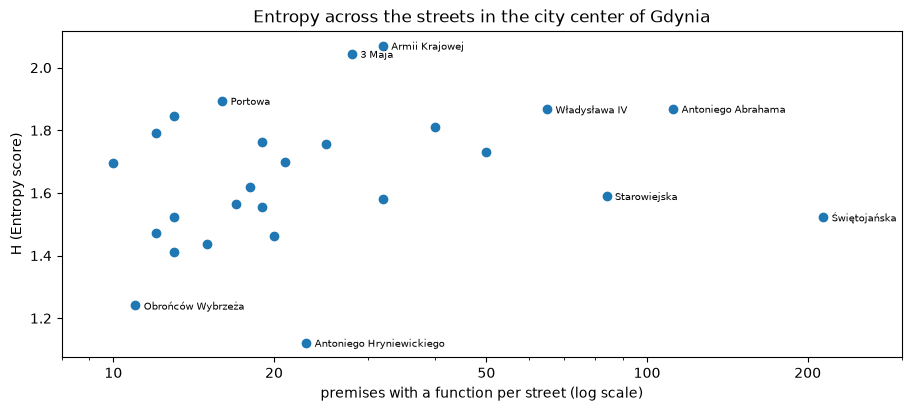

In [69]:
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.scatter(x= top_10['sum_all_prem_for_entropy'], y= top_10['entropy_score'])


ax.set_xlabel('premises with a function per street (log scale)')
ax.set_ylabel('H (Entropy score)')
ax.set_title('Entropy across the streets in the city center of Gdynia')

streets_to_show = ['Armii Krajowej', '3 Maja', 'Portowa', 'Antoniego Abrahama', 'Starowiejska', 'Świętojańska', 'Obrońców Wybrzeża', 'Antoniego Hryniewickiego', 'Władysława IV']
top_10_labels = top_10.loc[top_10['addr_street'].isin(streets_to_show)]

for ulica, x, y in zip(top_10_labels['addr_street'],top_10_labels['sum_all_prem_for_entropy'], top_10_labels['entropy_score']):
    ax.annotate(ulica, (x,y), xytext = (6,-3),textcoords="offset points", fontsize =7)



ax.set_xlim(8, 300)
ax.set_xscale("log")
ax.set_xticks([10, 20, 50, 100, 200])
ax.set_xticklabels(["10", "20", "50", "100", "200"])
plt.show()
fig.savefig("entropia_ulice.png", dpi=300)

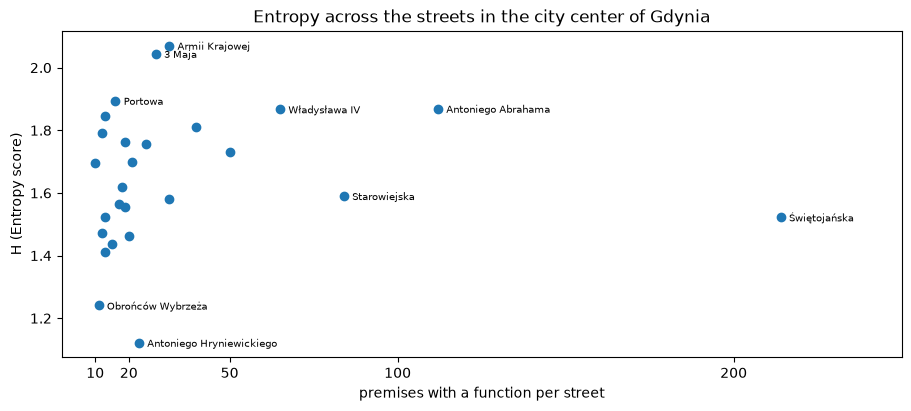

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.scatter(x= top_10['sum_all_prem_for_entropy'], y= top_10['entropy_score'])


ax.set_xlabel('premises with a function per street')
ax.set_ylabel('H (Entropy score)')
ax.set_title('Entropy across the streets in the city center of Gdynia')

streets_to_show = ['Armii Krajowej', '3 Maja', 'Portowa', 'Antoniego Abrahama', 'Starowiejska', 'Świętojańska', 'Obrońców Wybrzeża', 'Antoniego Hryniewickiego', 'Władysława IV']
top_10_labels = top_10.loc[top_10['addr_street'].isin(streets_to_show)]

for ulica, x, y in zip(top_10_labels['addr_street'],top_10_labels['sum_all_prem_for_entropy'], top_10_labels['entropy_score']):
    ax.annotate(ulica, (x,y), xytext = (6,-3),textcoords="offset points", fontsize =7)

ax.set_xlim(0, 250)
ax.set_xticks([10, 20, 50, 100, 200])
ax.set_xticklabels(["10", "20", "50", "100", "200"])
plt.show()

The functions in the Armi Krajowej streets are more equally distributed that leads to a really high Entropy score, when Świętojańska being the street with the most premises, but with not so equal distribution is sitting lower.
The big number of functions doesnt really decide on the Entropy score. 

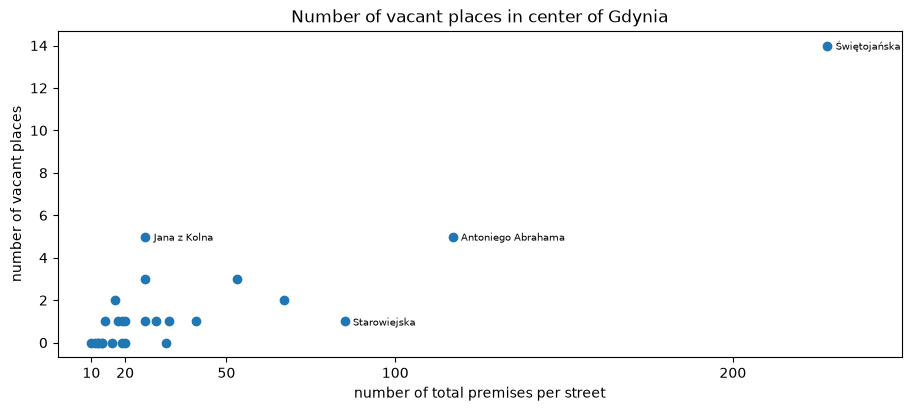

In [65]:
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.scatter(x= top_10['sum_all_prem'], y= top_10['num_vacant'])


ax.set_xlabel('number of total premises per street')
ax.set_ylabel('number of vacant places')
ax.set_title('Number of vacant places in center of Gdynia')

streets_to_show = ['Jana z Kolna', 'Antoniego Abrahama', 'Starowiejska', 'Świętojańska']
top_10_labels = top_10.loc[top_10['addr_street'].isin(streets_to_show)]

for ulica, x, y in zip(top_10_labels['addr_street'],top_10_labels['sum_all_prem'], top_10_labels['num_vacant']):
    ax.annotate(ulica, (x,y), xytext = (6,-3),textcoords="offset points", fontsize =7)

ax.set_xlim(0, 250)
ax.set_xticks([10, 20, 50, 100, 200])
ax.set_xticklabels(["10", "20", "50", "100", "200"])
plt.show()

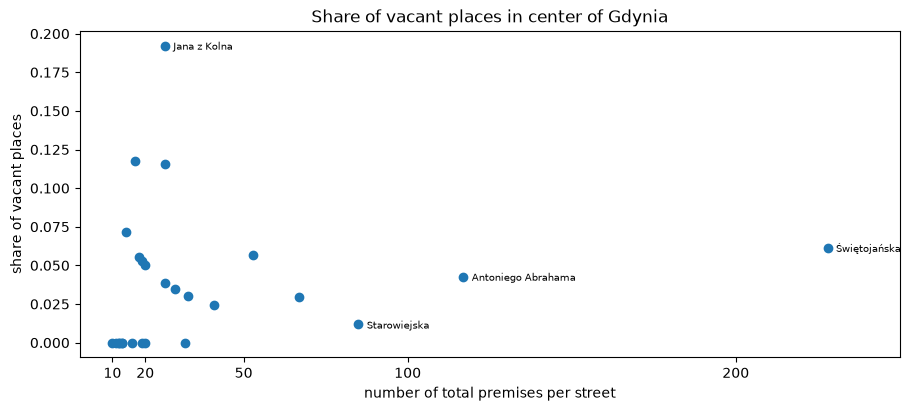

In [66]:
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.scatter(x= top_10['sum_all_prem'], y= top_10['share_vacant'])


ax.set_xlabel('number of total premises per street')
ax.set_ylabel('share of vacant places')
ax.set_title('Share of vacant places in center of Gdynia')

streets_to_show = ['Jana z Kolna', 'Antoniego Abrahama', 'Starowiejska', 'Świętojańska']
top_10_labels = top_10.loc[top_10['addr_street'].isin(streets_to_show)]

for ulica, x, y in zip(top_10_labels['addr_street'],top_10_labels['sum_all_prem'], top_10_labels['share_vacant']):
    ax.annotate(ulica, (x,y), xytext = (6,-3),textcoords="offset points", fontsize =7)

ax.set_xlim(0, 250)
ax.set_xticks([10, 20, 50, 100, 200])
ax.set_xticklabels(["10", "20", "50", "100", "200"])
plt.show()

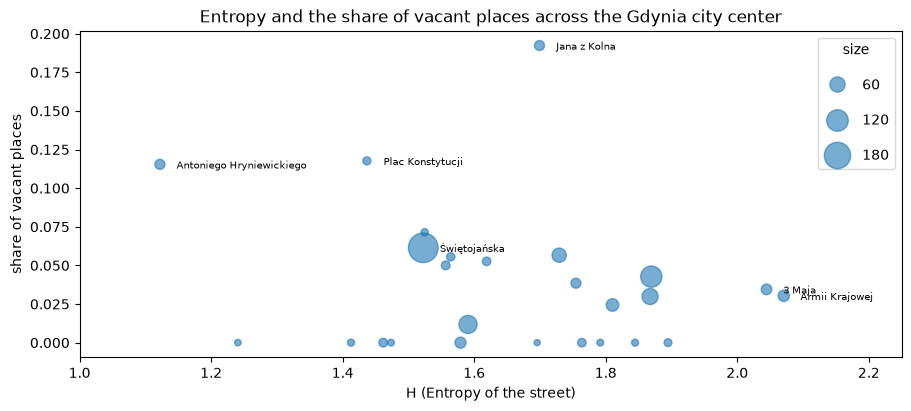

In [80]:
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
sc = ax.scatter(x= top_10['entropy_score'], y= top_10['share_vacant'] ,  s = top_10['sum_all_prem']*2, alpha=0.6)


ax.set_xlabel('H (Entropy of the street)')
ax.set_ylabel('share of vacant places')
ax.set_title('Entropy and the share of vacant places across the Gdynia city center')

streets_to_show = ['Jana z Kolna', 'Antoniego Hryniewickiego', 'Plac Konstytucji', 'Armii Krajowej', 'Świętojańska', '3 Maja']
top_10_labels = top_10.loc[top_10['addr_street'].isin(streets_to_show)]

for ulica, x, y in zip(top_10_labels['addr_street'],top_10_labels['entropy_score'], top_10_labels['share_vacant']):
    ax.annotate(ulica, (x,y), xytext = (12,-3),textcoords="offset points", fontsize =7)

uchwyty, podpisy = sc.legend_elements(prop="sizes", num=4,
                                      func=lambda s: s / 2,   # z pola z powrotem na lokale
                                      fmt="{x:.0f}", alpha=0.6, color = 'tab:blue')
ax.legend(uchwyty, podpisy, title="size", loc="upper right", labelspacing=1.5)

ax.set_xlim(1,2.25)
plt.show()
fig.savefig("entropia_vacant.png", dpi=300)